# BaCuSe XRD analysis

Reusable scan loading, preprocessing, reference matching, metric calculation, and plotting are implemented in `xrd_bo_optimization_tf`. Local `.xrdml` files belong in `data/raw/`; the processed metrics table is used when scans are not available.

In [3]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from xrd_bo_optimization_tf.config import (
    FIGURES_DIR,
    GENERATED_XRD_METRICS_CSV,
    NOMAD_STAGING_DIR,
    NOMAD_SYNTHESIS_CSV,
    SYNTHESIS_CSV,
    XRD_METRICS_CSV,
)
from xrd_bo_optimization_tf.phase_matching import analyze_pattern, load_reference_cards
from xrd_bo_optimization_tf.plotting import plot_all_xrd_patterns, plot_xrd_series
from xrd_bo_optimization_tf.xrd_io import load_xrd_data

# Prefer the complete NOMAD synthesis database; fall back to the legacy CSV.
synthesis_path = NOMAD_SYNTHESIS_CSV if NOMAD_SYNTHESIS_CSV.is_file() else SYNTHESIS_CSV
df_synth_csv = pd.read_csv(synthesis_path)
print(f'Synthesis source: {synthesis_path} ({len(df_synth_csv)} samples)')

references = load_reference_cards()
# XRD scans come from the NOMAD archives staged by notebook 1 (source='nomad').
xrd_raw = load_xrd_data(
    df_synth_csv['sample_id'].astype(str).tolist(),
    source='nomad',
    nomad_archive_root=NOMAD_STAGING_DIR,
)
print(f'Loaded {len(xrd_raw)} XRD scans for {len(df_synth_csv)} synthesis records')

Synthesis source: /home/nomad-lanasc/xrd-bo-optimization-tf/data/processed/bacuse2_synthesis_database_nomad.csv (42 samples)
Loaded 25 XRD scans for 42 synthesis records


In [4]:
xrd_results = {
    sample_id: analyze_pattern(scan['two_theta'], scan['intensity'], references)
    for sample_id, scan in xrd_raw.items()
}

metrics_path = (
    GENERATED_XRD_METRICS_CSV
    if GENERATED_XRD_METRICS_CSV.is_file()
    else XRD_METRICS_CSV
)
existing_metrics = pd.read_csv(metrics_path)
if xrd_results:
    synthesis_lookup = df_synth_csv.drop_duplicates('sample_id').set_index('sample_id')
    rows = []
    for sample_id, result in sorted(xrd_results.items()):
        if sample_id not in synthesis_lookup.index:
            continue
        synthesis = synthesis_lookup.loc[sample_id]
        rows.append({
            'sample_id': sample_id,
            'series': synthesis['series'],
            'crystallinity': result['crystallinity'],
            'primary_fwhm': result['primary_fwhm'],
            'phase_purity': result['phase_purity'],
            'n_detected_peaks': result['n_detected_peaks'],
            'n_target_matches': result['n_target_matches'],
            **{column: synthesis.get(column) for column in (
                'spin_speed_rpm', 'soft_bake_temp_c', 'hard_bake_temp_c',
                'selenization_temp_c', 'selenization_time_s',
            )},
        })
    analyzed_metrics = pd.DataFrame(rows)
    if not analyzed_metrics.empty:
        updated_ids = set(analyzed_metrics['sample_id'].astype(str))
        existing_metrics = existing_metrics.loc[
            ~existing_metrics['sample_id'].astype(str).isin(updated_ids)
        ]
        df_metrics = pd.concat([existing_metrics, analyzed_metrics], ignore_index=True)
        GENERATED_XRD_METRICS_CSV.parent.mkdir(parents=True, exist_ok=True)
        df_metrics.to_csv(GENERATED_XRD_METRICS_CSV, index=False)
        print(f'Wrote {len(analyzed_metrics)} new or updated scan metrics to {GENERATED_XRD_METRICS_CSV}')
    else:
        df_metrics = existing_metrics
        print('No XRD scans matched the synthesis table; kept the existing metrics')
else:
    df_metrics = existing_metrics
    print(f'No XRD scans found; loaded existing metrics from {metrics_path}')

df_metrics.head()

Wrote 25 new or updated scan metrics to /home/nomad-lanasc/xrd-bo-optimization-tf/data/results/bacuse2_xrd_analysis_metrics.csv


,sample_id,series,crystallinity,primary_fwhm,phase_purity,n_detected_peaks,n_target_matches,spin_speed_rpm,soft_bake_temp_c,hard_bake_temp_c,selenization_temp_c,selenization_time_s
0,260429A11,260429A,1.173311,0.852289,0.809015,5,2,2000.0,100.0,250.0,520.0,600.0
1,260429A12,260429A,1.347782,0.741960,1.000000,4,2,2000.0,100.0,250.0,520.0,600.0
2,260429A2,260429A,NaN,NaN,0.000000,2,0,2000.0,100.0,250.0,540.0,1200.0
3,260429A3,260429A,2.205827,0.453345,1.000000,4,3,2000.0,100.0,250.0,560.0,1800.0
4,260429B1,260429B,1.821664,0.548949,1.000000,4,1,2000.0,100.0,250.0,520.0,1200.0


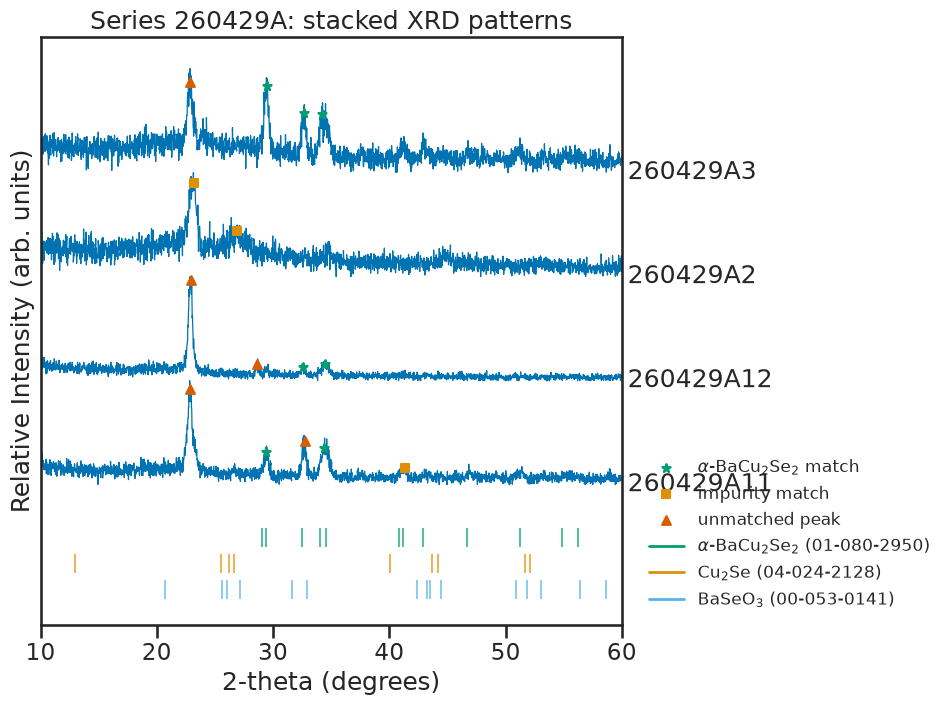

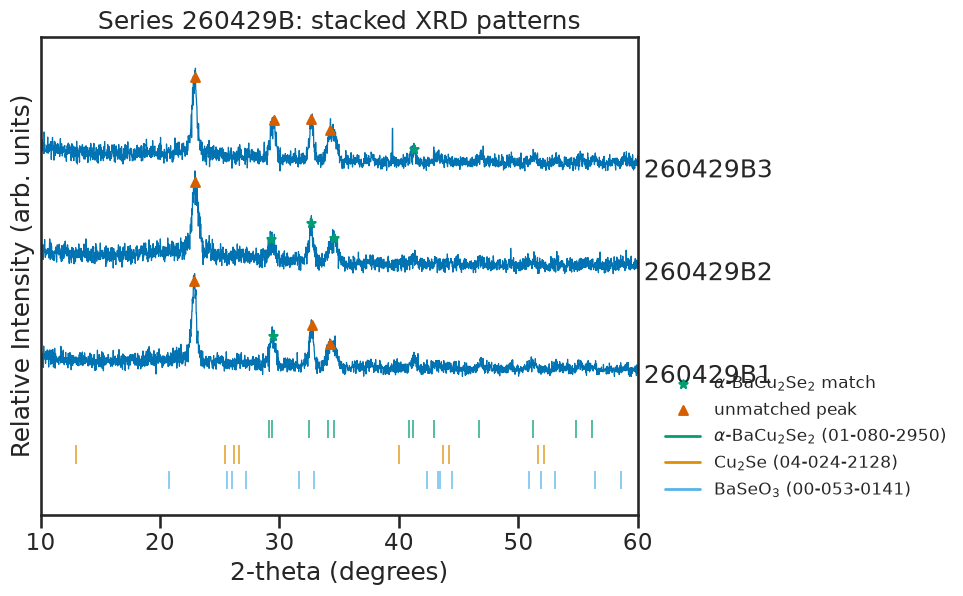

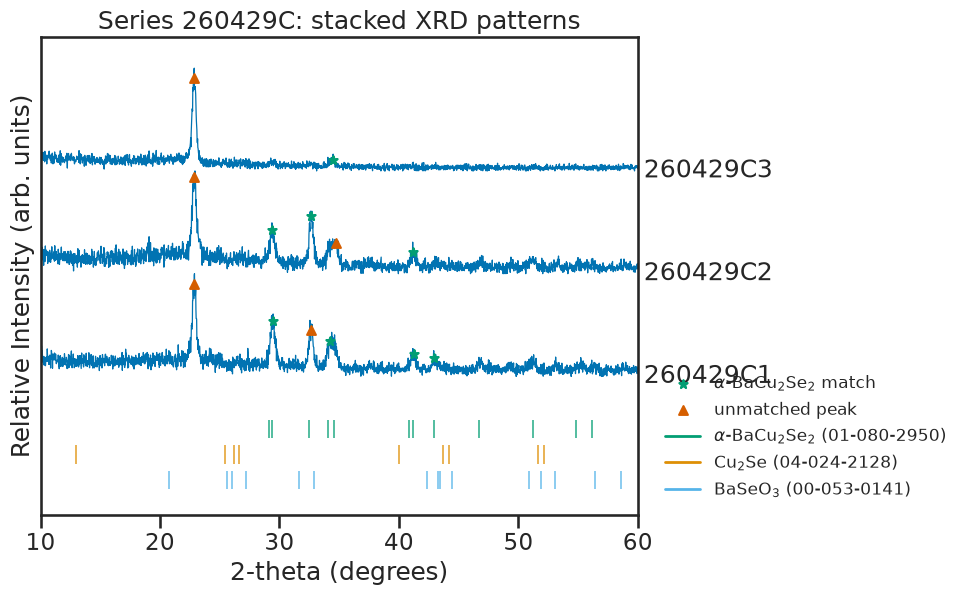

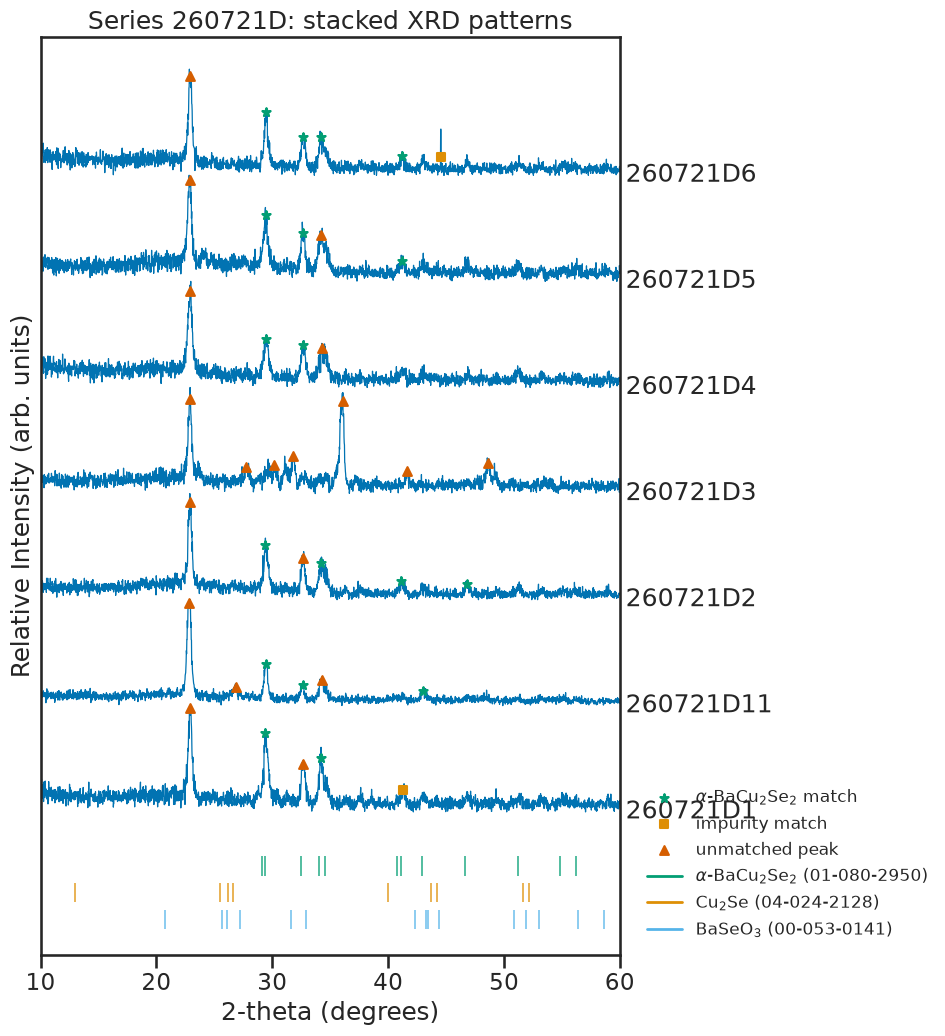

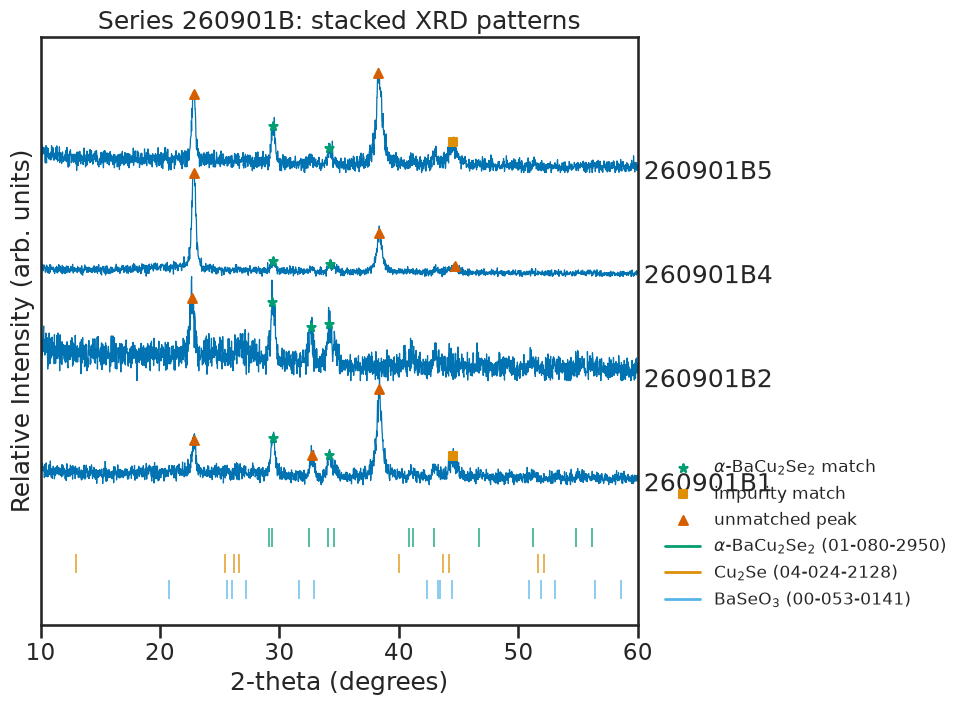

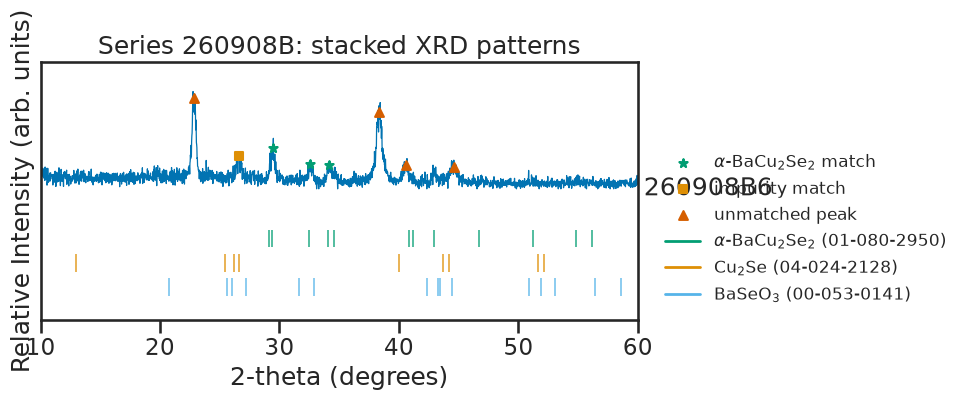

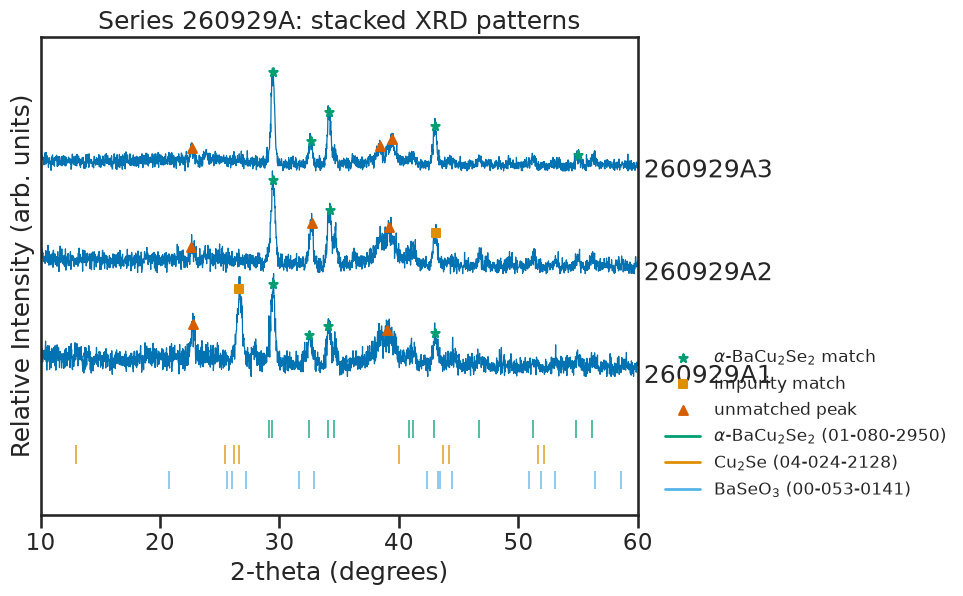

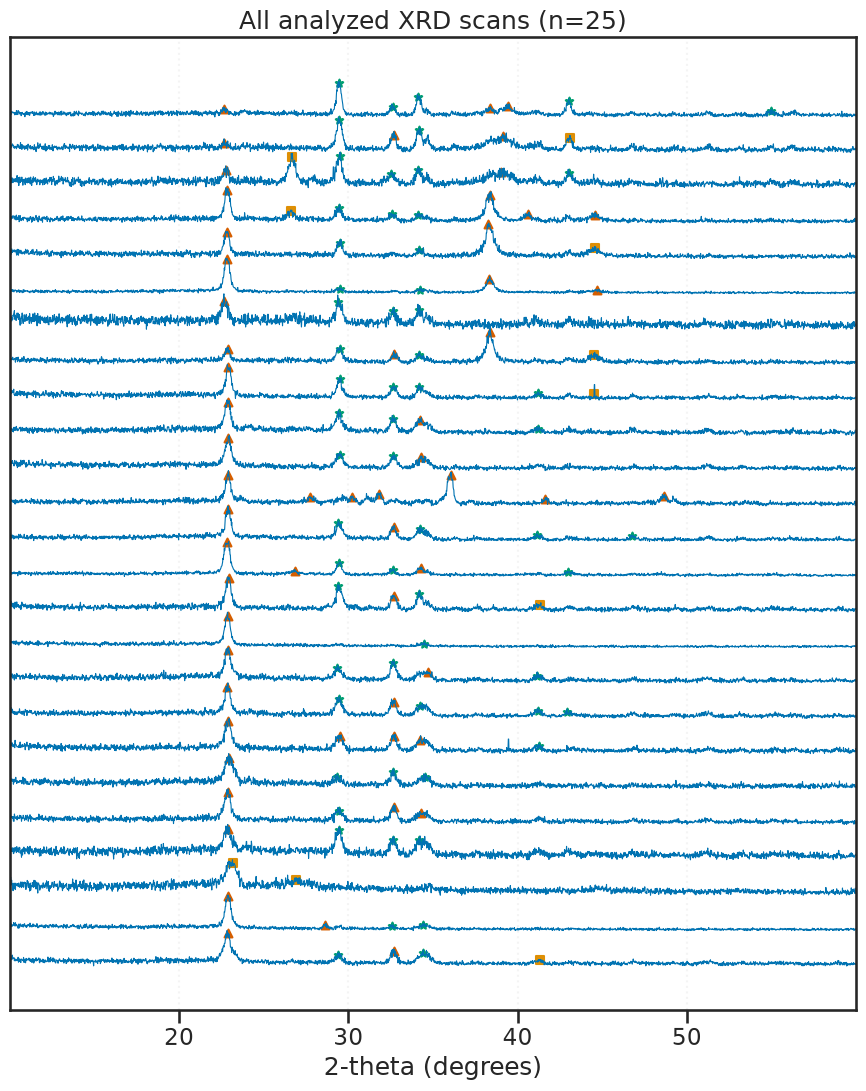

In [5]:
series_figures = plot_xrd_series(xrd_results, df_metrics, references)
all_scans_figure = plot_all_xrd_patterns(
    xrd_results, df_metrics,
    output_path=FIGURES_DIR / 'bacuse2_xrd_all_samples.png',
)
if series_figures or all_scans_figure is not None:
    plt.show()
else:
    print('Plots will be available when XRD scans are added to data/raw/')

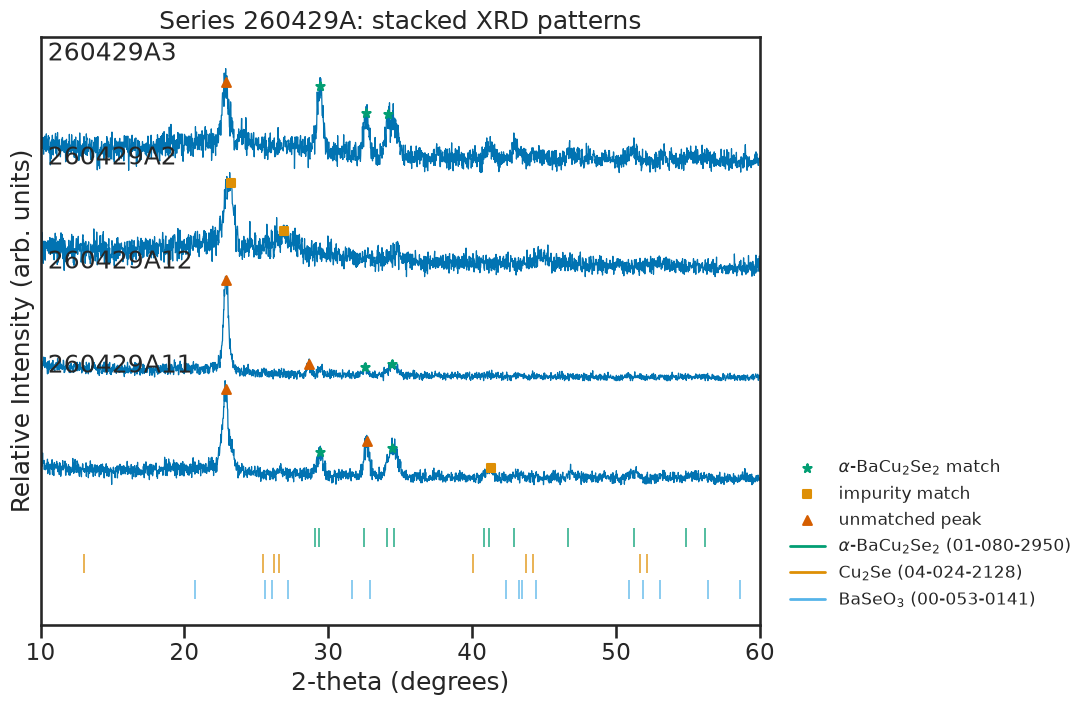

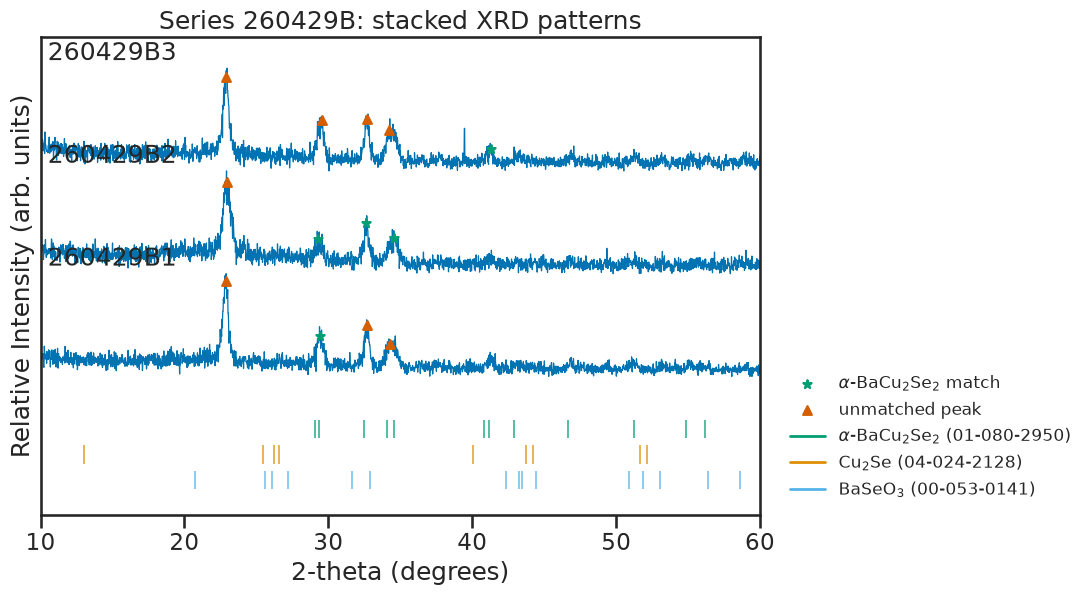

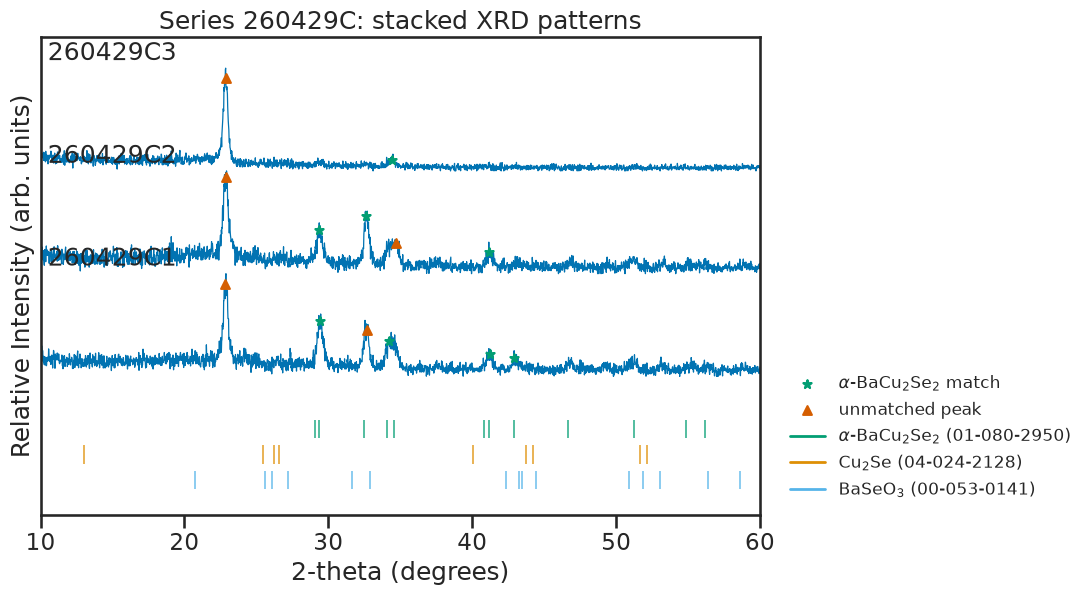

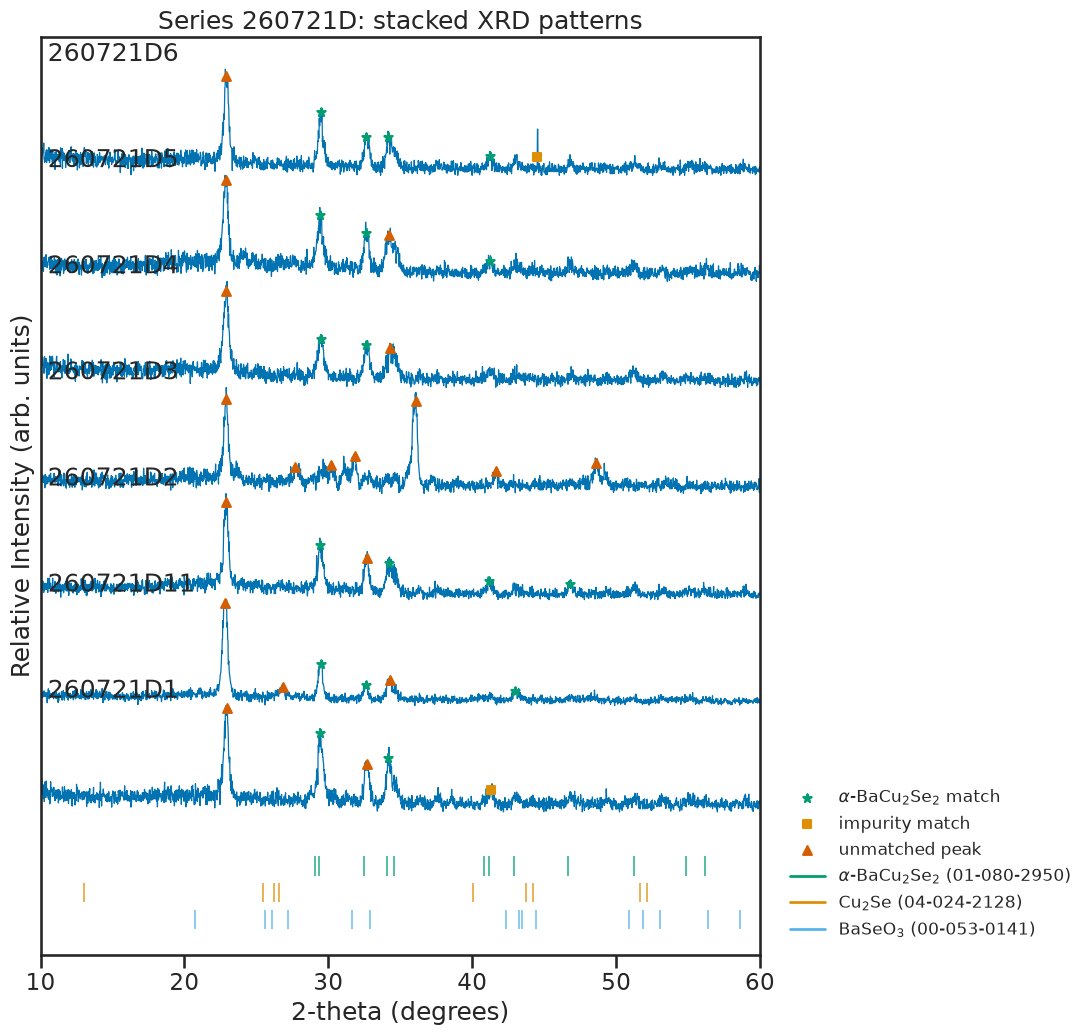

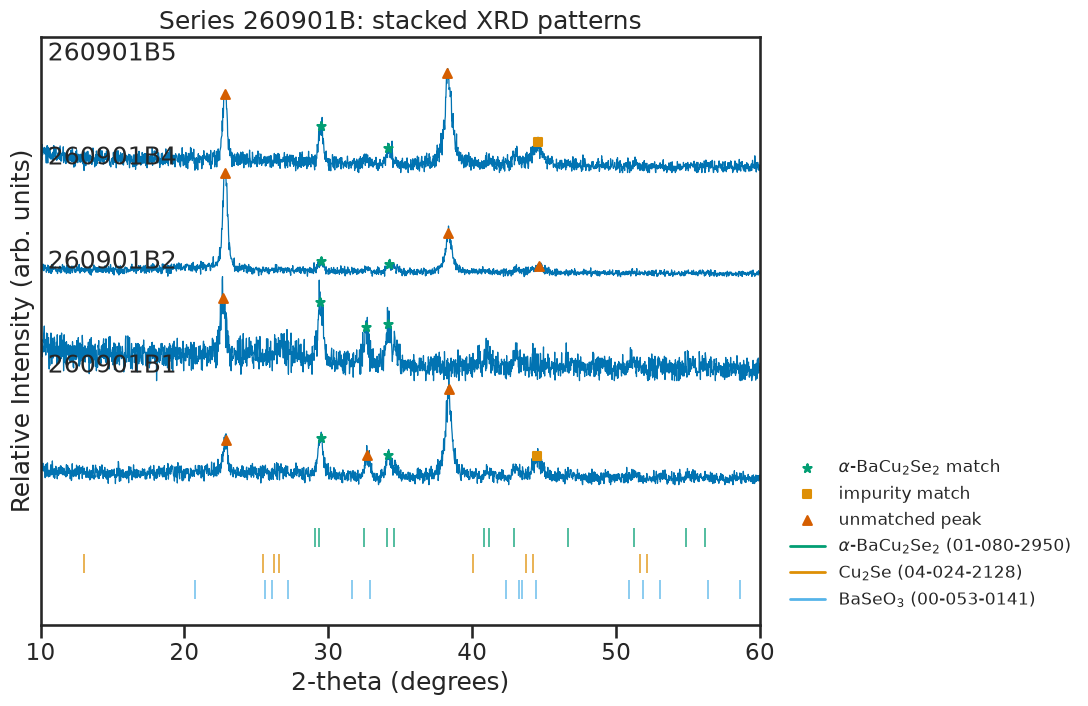

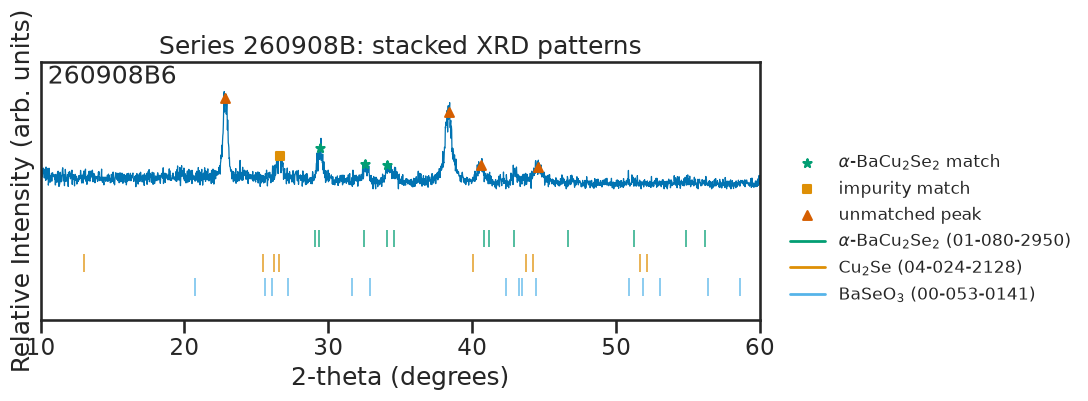

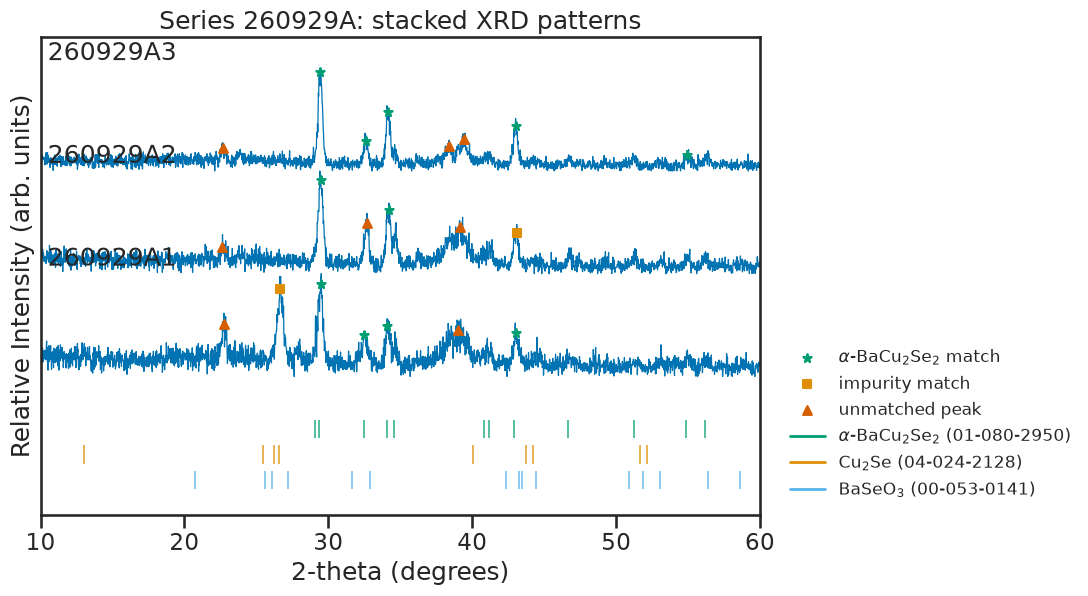

In [7]:
import importlib
import xrd_bo_optimization_tf.plotting as plotting

importlib.reload(plotting)
series_figures = plotting.plot_xrd_series(xrd_results, df_metrics, references)
plt.show()

In [6]:
summary_columns = [column for column in (
    'crystallinity', 'phase_purity', 'primary_fwhm', 'n_detected_peaks',
) if column in df_metrics]
df_metrics.groupby('series')[summary_columns].agg(['count', 'mean', 'min', 'max']).round(3)

crystallinity                      phase_purity                       \
                count   mean    min    max        count   mean    min    max   
series                                                                         
260429A             3  1.576  1.173  2.206            4  0.702  0.000  1.000   
260429B             3  2.139  1.679  2.915            3  1.000  1.000  1.000   
260429C             3  2.031  1.626  2.386            3  1.000  1.000  1.000   
260721D             6  2.422  1.966  2.886            6  0.958  0.833  1.000   
260901B             4  2.263  1.982  2.458            4  0.834  0.649  1.000   
260908B             1  2.273  2.273  2.273            1  0.717  0.717  0.717   
260929A             3  2.591  2.425  2.830            3  0.834  0.714  1.000   

        primary_fwhm                      n_detected_peaks                 
               count   mean    min    max            count   mean min max  
series                                                                     
260429A            3  0.683  0.453  0.852                4  3.750   2   5  
260429B            3  0.496  0.343  0.596                3  4.333   4   5  
260429C            3  0.505  0.419  0.615                3  4.333   2   6  
260721D            6  0.419  0.347  0.509                7  5.571   4   7  
260901B            4  0.445  0.407  0.505                4  5.000   4   6  
260908B            1  0.440  0.440  0.440                1  8.000   8   8  
260929A            3  0.388  0.353  0.412                3  7.000   6   8